# 01 · Data understanding and preprocessing

EDA of the 63 labelled VisDrone-VID clips (train + val pooled) and the 48 test clips.
Figures are saved to `images/` for the report. Runs on CPU in a few minutes.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from hw2 import CLASSES
from hw2.data import load_all, load_test, make_folds, subsample, fold_frames
from hw2.prep import _process

IMG = Path("../images"); IMG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.9)
pd.set_option("display.width", 160)

frames, boxes = load_all()
test = load_test()
folds = make_folds(frames)
frames = frames.merge(folds[["clip", "fold"]], on="clip")

## 1. Clips, frames and resolutions

In [2]:
# long side is capped at 1920 by our preprocessing (largest test resolution)
for df in (frames, test):
    df["scale"] = np.minimum(1.0, 1920 / df[["width", "height"]].max(axis=1))
    df["res"] = df.width.astype(str) + "x" + df.height.astype(str)

summary = pd.DataFrame({
    "clips": [frames.query("split=='train'")["clip"].nunique(), frames.query("split=='val'")["clip"].nunique(), test["clip"].nunique()],
    "frames": [(frames.split == "train").sum(), (frames.split == "val").sum(), len(test)],
}, index=["train", "val", "test"])
display(summary)

res = pd.concat([frames.assign(set=frames.split), test.assign(set="test")])
display(pd.crosstab(res.res, res.set))
clip_len = pd.concat([frames.groupby("clip").size().rename("labelled"), test.groupby("clip").size().rename("test")], axis=1)
display(clip_len.describe().round(0))

,clips,frames
train,56,24201
val,7,2846
test,48,3811


set,test,train,val
res,,,
1344x756,441,5645,827
1360x764,1474,0,0
1360x765,0,962,0
1904x1071,0,12895,459
1904x1072,305,0,0
1920x1080,991,721,0
2688x1512,0,3505,233
2720x1530,0,473,349
3840x2160,0,0,978


,labelled,test
count,63.0,48.0
mean,429.0,79.0
std,272.0,35.0
min,58.0,35.0
25%,228.0,49.0
50%,363.0,74.0
75%,548.0,108.0
max,1424.0,148.0


Test frames are at most 1920x1080 and include 680x382 / 960x540 clips that do not exist in the
labelled data, while some labelled clips are 2.7K-4K. Test clips are also much shorter (35-148 frames).

## 2. Annotations: classes, ignored regions, occlusion

In [3]:
valid = boxes[boxes.ignore == 0].merge(frames[["key", "clip", "frame", "fold", "scale", "width", "height"]], on="key")
ign = boxes[boxes.ignore == 1].merge(frames[["key", "clip", "width", "height"]], on="key")
valid["name"] = valid.cls.map(dict(enumerate(CLASSES)))

# original VisDrone categories behind the 8 target classes and the ignored rows
VISDRONE = {0: "ignored region", 1: "pedestrian", 2: "people", 3: "bicycle", 4: "car", 5: "van", 6: "truck",
            7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor", 11: "others"}
m = boxes.assign(orig=boxes.orig_cls.map(VISDRONE),
                 target=np.where(boxes.ignore == 1, "ignore", boxes.cls.map(dict(enumerate(CLASSES)))))
display(pd.crosstab(m.orig, m.target))

target,bicycle,bus,car,ignore,motor,person,tricycle,truck,van
orig,,,,,,,,,
awning-tricycle,0,0,0,0,0,0,14729,0,0
bicycle,46277,0,0,0,0,0,0,0,0
bus,0,9917,0,0,0,0,0,0,0
car,0,0,537122,0,0,0,0,0,0
ignored region,0,0,0,530904,0,0,0,0,0
motor,0,0,0,0,114844,0,0,0,0
others,0,0,0,11800,0,0,0,0,0
pedestrian,0,0,0,0,0,266709,0,0,0
people,0,0,0,0,0,112304,0,0,0


`pedestrian` and `people` are merged into `person`, `awning-tricycle` into `tricycle`; VisDrone
`ignored region` and `others` become don't-care regions (iscrowd=1).

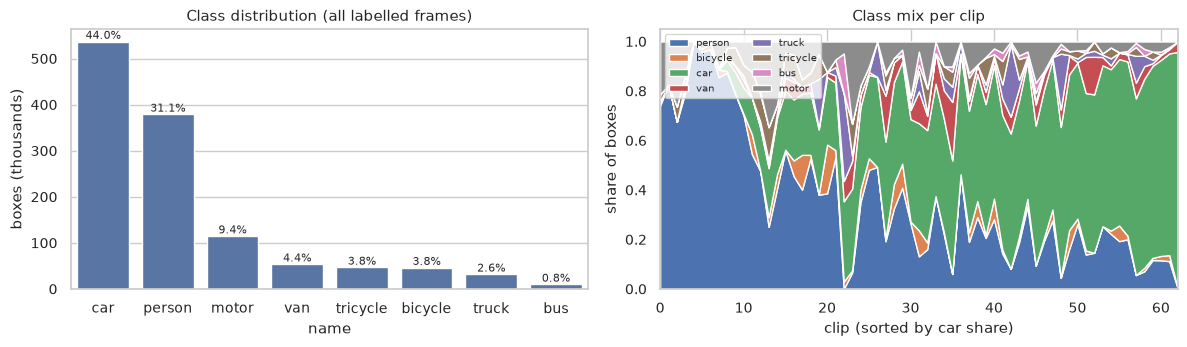

clips containing each class: {'bicycle': 46, 'bus': 25, 'car': 55, 'motor': 56, 'person': 62, 'tricycle': 44, 'truck': 44, 'van': 52}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
cnt = valid.name.value_counts()
sns.barplot(x=cnt.index, y=cnt.values / 1e3, ax=ax[0], color="C0")
ax[0].set(ylabel="boxes (thousands)", title="Class distribution (all labelled frames)")
for i, v in enumerate(cnt.values):
    ax[0].text(i, v / 1e3, f"{v / cnt.sum():.1%}", ha="center", va="bottom", fontsize=8)
share = pd.crosstab(valid["clip"], valid.name, normalize="index")[CLASSES]
share = share.loc[share["car"].sort_values().index]
ax[1].stackplot(range(len(share)), share.T.values, labels=CLASSES)
ax[1].set(xlabel="clip (sorted by car share)", ylabel="share of boxes", title="Class mix per clip", xlim=(0, len(share) - 1))
ax[1].legend(fontsize=7, ncol=2, loc="upper left")
plt.tight_layout(); plt.savefig(IMG / "eda_classes.png", dpi=130); plt.show()

print("clips containing each class:", (pd.crosstab(valid["clip"], valid.name) > 0).sum().to_dict())

In [5]:
occ = pd.crosstab(valid.name, valid.occlusion, normalize="index").rename(columns={0: "none", 1: "partial", 2: "heavy"})
display(occ.round(3))
fr_ign = ign.groupby("key").apply(lambda g: (g.w * g.h).sum() / (g.width.iloc[0] * g.height.iloc[0]), include_groups=False)
print(f"frames with ignored regions: {ign.key.nunique() / len(frames):.1%}; "
      f"median ignored area in those frames: {fr_ign.median():.1%}, 90th pct: {fr_ign.quantile(.9):.1%}")

occlusion,none,partial,heavy
name,,,
bicycle,0.417,0.551,0.032
bus,0.566,0.413,0.020
car,0.562,0.389,0.049
motor,0.519,0.417,0.064
person,0.530,0.409,0.061
tricycle,0.417,0.556,0.026
truck,0.346,0.498,0.156
van,0.549,0.415,0.035


frames with ignored regions: 72.2%; median ignored area in those frames: 13.1%, 90th pct: 65.4%


## 3. Object sizes

COCO buckets at model input: small 49.7%, medium 46.8%, large 3.5%
size percentiles (5/25/50/75/95) at model input: [14.2 22.9 32.1 46.2 86.8]


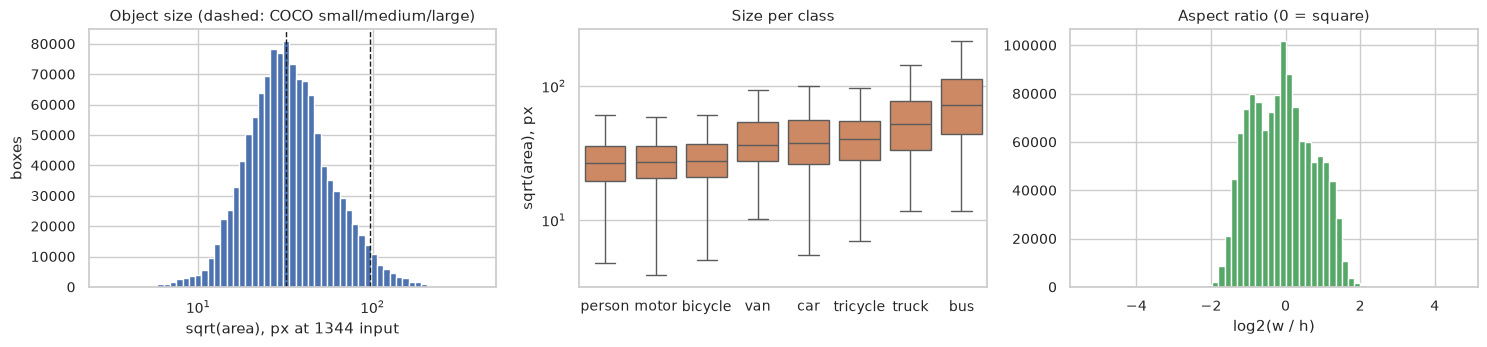

median object size per clip ranges from 17 to 61 px


In [6]:
# size = sqrt(area) in pixels after our 1920 cap, and at the 1344-px model input used in all experiments
valid["size"] = np.sqrt(valid.w * valid.h) * valid.scale
valid["size_model"] = np.sqrt(valid.w * valid.h) * 1344 / valid[["width", "height"]].max(axis=1)
area = valid.size_model ** 2
print("COCO buckets at model input: small {:.1%}, medium {:.1%}, large {:.1%}".format(
    (area < 32**2).mean(), ((area >= 32**2) & (area < 96**2)).mean(), (area >= 96**2).mean()))
print("size percentiles (5/25/50/75/95) at model input:", np.percentile(valid.size_model, [5, 25, 50, 75, 95]).round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(valid.size_model, bins=np.logspace(np.log10(3), np.log10(400), 60), color="C0")
ax[0].set_xscale("log"); ax[0].axvline(32, c="k", ls="--", lw=1); ax[0].axvline(96, c="k", ls="--", lw=1)
ax[0].set(xlabel="sqrt(area), px at 1344 input", ylabel="boxes", title="Object size (dashed: COCO small/medium/large)")
order = valid.groupby("name").size_model.median().sort_values().index
sns.boxplot(data=valid, x="name", y="size_model", order=order, showfliers=False, ax=ax[1], color="C1")
ax[1].set(yscale="log", xlabel="", ylabel="sqrt(area), px", title="Size per class")
ax[2].hist(np.log2(valid.w / valid.h), bins=60, color="C2")
ax[2].set(xlabel="log2(w / h)", title="Aspect ratio (0 = square)")
plt.tight_layout(); plt.savefig(IMG / "eda_sizes.png", dpi=130); plt.show()

per_clip = valid.groupby("clip").size_model.median()
print("median object size per clip ranges from {:.0f} to {:.0f} px".format(per_clip.min(), per_clip.max()))

## 4. Scene density

objects per frame percentiles (5/50/95/max): [  6.  42. 111. 180.]


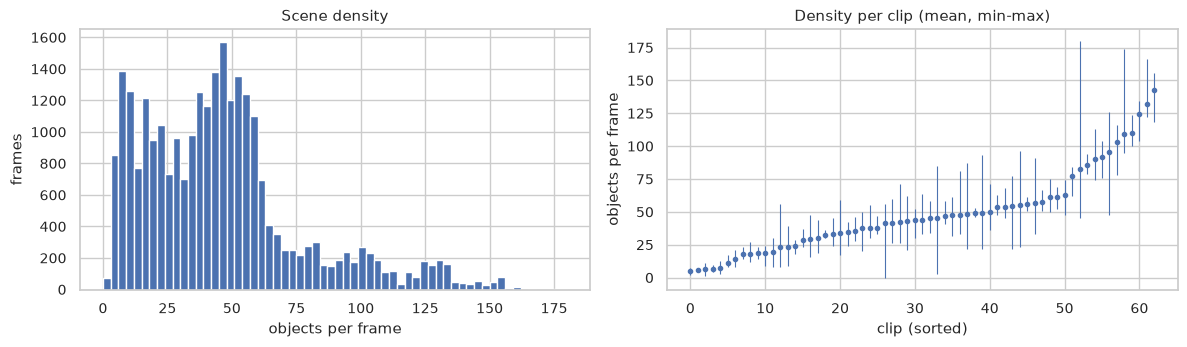

In [7]:
n_obj = valid.groupby("key").size().reindex(frames.key, fill_value=0)
frames["n_obj"] = n_obj.values
print("objects per frame percentiles (5/50/95/max):", np.percentile(frames.n_obj, [5, 50, 95, 100]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(frames.n_obj, bins=60, color="C0"); ax[0].set(xlabel="objects per frame", ylabel="frames", title="Scene density")
g = frames.groupby("clip").n_obj.agg(["mean", "min", "max"]).sort_values("mean")
ax[1].errorbar(range(len(g)), g["mean"], yerr=[g["mean"] - g["min"], g["max"] - g["mean"]], fmt="o", ms=3, lw=0.8)
ax[1].set(xlabel="clip (sorted)", ylabel="objects per frame", title="Density per clip (mean, min-max)")
plt.tight_layout(); plt.savefig(IMG / "eda_density.png", dpi=130); plt.show()

## 5. Temporal redundancy and frame subsampling

IoU of the same track (track_id) between frame t and t+k measures how much consecutive frames repeat.

In [8]:
def iou_xywh(a, b):
    x1 = np.maximum(a[:, 0], b[:, 0]); y1 = np.maximum(a[:, 1], b[:, 1])
    x2 = np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]); y2 = np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)

t = valid[["clip", "track_id", "frame", "x", "y", "w", "h"]]
rows = []
for k in [1, 2, 5, 10, 20, 40]:
    mm = t.merge(t.assign(frame=t.frame - k), on=["clip", "track_id", "frame"])
    iou = iou_xywh(mm[["x_x", "y_x", "w_x", "h_x"]].values, mm[["x_y", "y_y", "w_y", "h_y"]].values)
    rows.append({"gap": k, "median IoU": np.median(iou), "IoU>0.5": (iou > 0.5).mean(), "track still present": len(mm) / len(t)})
temporal = pd.DataFrame(rows).round(3); display(temporal)

for step in [1, 2, 5, 10]:
    print(f"step {step:2d}: {len(subsample(frames, step)):6d} labelled frames")

,gap,median IoU,IoU>0.5,track still present
0,1,0.895,0.952,0.993
1,2,0.806,0.851,0.986
2,5,0.591,0.586,0.966
3,10,0.348,0.387,0.932
4,20,0.093,0.254,0.870
5,40,0.000,0.181,0.756


step  1:  27047 labelled frames
step  2:  13539 labelled frames
step  5:   5439 labelled frames
step 10:   2734 labelled frames


## 6. Clip-level folds

5-fold GroupKFold by clip over all 63 labelled clips. All model comparisons use fold 0 as validation
(compute budget); frames of one clip never appear on both sides.

In [9]:
fs = frames.groupby("fold").agg(clips=("clip", "nunique"), frames=("key", "size"), objects_per_frame=("n_obj", "mean"))
fs = fs.join(pd.crosstab(valid.fold, valid.name, normalize="index")[CLASSES].round(3))
display(fs)

,clips,frames,objects_per_frame,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,,,,
0,12,5399,51.772921,0.331,0.058,0.449,0.026,0.006,0.027,0.003,0.100
1,13,5446,38.742931,0.357,0.038,0.369,0.051,0.028,0.029,0.007,0.122
2,12,5370,48.006890,0.278,0.023,0.472,0.055,0.028,0.051,0.012,0.080
3,13,5419,48.129913,0.304,0.037,0.377,0.059,0.032,0.065,0.011,0.116
4,13,5413,38.891373,0.287,0.030,0.541,0.028,0.042,0.014,0.009,0.050


## 7. Anchor statistics

k-means (IoU distance, YOLOv2-style) on box sizes at the 1344 model input, and how well the default
torchvision anchors cover the boxes (best IoU between a box and any anchor shape, centred).

In [10]:
wh = (valid[["w", "h"]].values * (1344 / valid[["width", "height"]].max(axis=1).values)[:, None]).astype(np.float32)
rng = np.random.default_rng(0)
sample = wh[rng.choice(len(wh), 50000, replace=False)]

def wh_iou(a, b):  # centred boxes
    inter = np.minimum(a[:, None, 0], b[None, :, 0]) * np.minimum(a[:, None, 1], b[None, :, 1])
    return inter / (a[:, None].prod(-1) + b[None].prod(-1) - inter)

def kmeans_iou(x, k, iters=50):
    c = x[rng.choice(len(x), k, replace=False)]
    for _ in range(iters):
        a = wh_iou(x, c).argmax(1)
        c = np.array([np.median(x[a == j], 0) if (a == j).any() else c[j] for j in range(k)])
    return c[np.argsort(c.prod(1))]

centers = kmeans_iou(sample, 9)
print("k-means anchors (w, h):", centers.round(1).tolist())
print("k-means anchor sqrt(area):", np.sqrt(centers.prod(1)).round(1).tolist())

def anchor_shapes(sizes, ratios=(0.5, 1.0, 2.0)):  # torchvision: ratio = h / w
    return np.array([[s / np.sqrt(r), s * np.sqrt(r)] for s in sizes for r in ratios])

frcnn_default = anchor_shapes([32, 64, 128, 256, 512])
frcnn_small = anchor_shapes([16, 32, 64, 128, 256])
retina_default = anchor_shapes([s * 2 ** (i / 3) for s in [32, 64, 128, 256, 512] for i in range(3)])
retina_small = anchor_shapes([s * 2 ** (i / 3) for s in [12, 24, 48, 96, 192] for i in range(3)])
cov = {}
for name, a in [("FRCNN default (32-512)", frcnn_default), ("FRCNN tuned (16-256)", frcnn_small),
                ("RetinaNet default (32-512)", retina_default), ("RetinaNet tuned (12-192)", retina_small),
                ("k-means 9", centers)]:
    best = wh_iou(sample, a).max(1)
    cov[name] = {"mean best IoU": best.mean(), "boxes with IoU>=0.5": (best >= 0.5).mean(),
                 "boxes with IoU>=0.4": (best >= 0.4).mean()}
display(pd.DataFrame(cov).T.round(3))

k-means anchors (w, h): [[12.0, 16.5], [16.200000762939453, 32.5], [24.0, 24.0], [37.400001525878906, 19.100000381469727], [25.399999618530273, 48.0], [39.5, 32.5], [71.30000305175781, 37.5], [47.29999923706055, 63.5], [112.19999694824219, 79.80000305175781]]
k-means anchor sqrt(area): [14.100000381469727, 23.0, 24.0, 26.700000762939453, 34.900001525878906, 35.79999923706055, 51.70000076293945, 54.79999923706055, 94.5999984741211]


,mean best IoU,boxes with IoU>=0.5,boxes with IoU>=0.4
FRCNN default (32-512),0.603,0.752,0.817
FRCNN tuned (16-256),0.692,0.980,0.987
RetinaNet default (32-512),0.668,0.752,0.817
RetinaNet tuned (12-192),0.823,0.992,0.996
k-means 9,0.725,0.959,0.983


## 8. Annotation conversion check

Left: original frame with GT boxes (green) and ignored regions (red). Right: the prepared training
frame (ignored regions filled with gray except where they overlap a valid box) with boxes read back
from the YOLO label file.

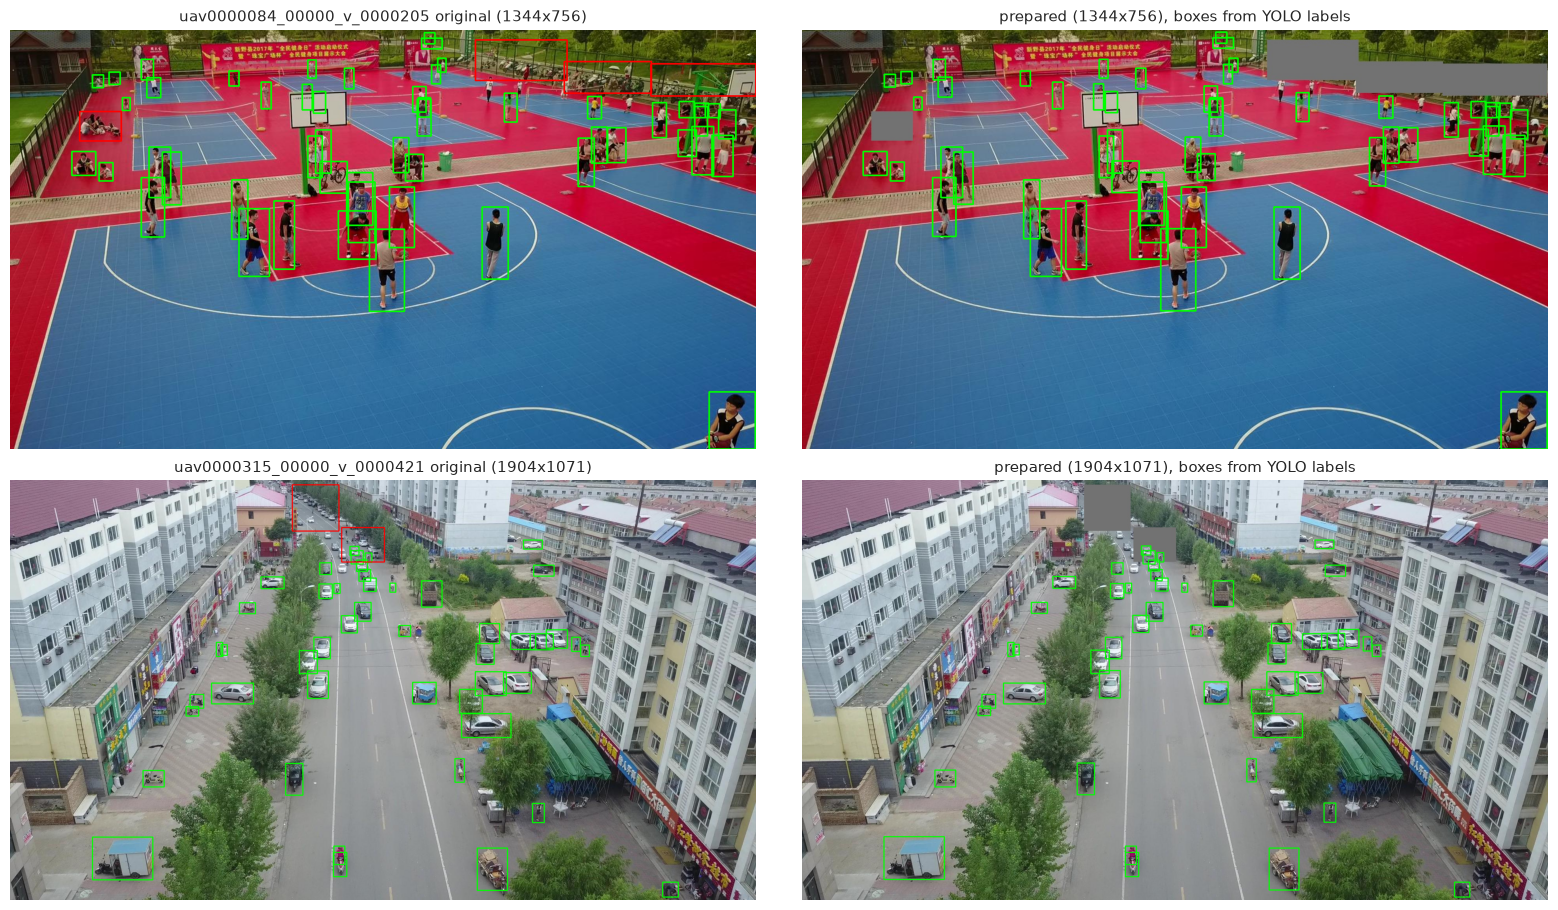

In [11]:
import tempfile
tmp = Path(tempfile.mkdtemp())
picks = [frames.loc[frames.key.isin(ign.key)].sample(1, random_state=s).iloc[0] for s in (1, 7)]
fig, axes = plt.subplots(len(picks), 2, figsize=(16, 4.6 * len(picks)))
for (a0, a1), r in zip(axes, picks):
    g = boxes[boxes.key == r.key]
    img = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)
    for b in g.itertuples():
        col = (255, 0, 0) if b.ignore else (0, 255, 0)
        cv2.rectangle(img, (int(b.x), int(b.y)), (int(b.x + b.w), int(b.y + b.h)), col, max(2, img.shape[1] // 700))
    a0.imshow(img); a0.set_title(f"{r.key} original ({r.width}x{r.height})"); a0.axis("off")

    v = g.loc[g.ignore == 0, ["cls", "x", "y", "w", "h"]].to_numpy(np.float32)
    i = g.loc[g.ignore == 1, ["x", "y", "w", "h"]].to_numpy(np.float32)
    W, H = _process((r.path, str(tmp / "p.jpg"), str(tmp / "p.txt"), v, i))
    p = cv2.cvtColor(cv2.imread(str(tmp / "p.jpg")), cv2.COLOR_BGR2RGB)
    for line in open(tmp / "p.txt"):
        c, cx, cy, w, h = map(float, line.split())
        cv2.rectangle(p, (int((cx - w / 2) * W), int((cy - h / 2) * H)), (int((cx + w / 2) * W), int((cy + h / 2) * H)), (0, 255, 0), 2)
    a1.imshow(p); a1.set_title(f"prepared ({W}x{H}), boxes from YOLO labels"); a1.axis("off")
plt.tight_layout(); plt.savefig(IMG / "eda_conversion.png", dpi=110); plt.show()

In [12]:
# numbers referenced in the report
facts = {
    "labelled_clips": int(frames["clip"].nunique()), "labelled_frames": len(frames), "test_frames": len(test),
    "boxes": len(valid), "ignored_regions": len(ign),
    "median_size_px_1344": float(np.median(valid.size_model)), "coco_small_share": float((area < 32**2).mean()),
    "median_objects_per_frame": float(np.median(frames.n_obj)), "max_objects_per_frame": int(frames.n_obj.max()),
    "class_share": (cnt / cnt.sum()).round(4).to_dict(),
    "kmeans_anchor_sizes": np.sqrt(centers.prod(1)).round(1).tolist(),
    "temporal_median_iou": dict(zip(temporal.gap.astype(str), temporal["median IoU"])),
}
Path("../results").mkdir(exist_ok=True)
Path("../results/eda_facts.json").write_text(json.dumps(facts, indent=1))
facts

{'labelled_clips': 63,
 'labelled_frames': 27047,
 'test_frames': 3811,
 'boxes': 1219648,
 'ignored_regions': 542704,
 'median_size_px_1344': 32.10018997833508,
 'coco_small_share': 0.4966260757202078,
 'median_objects_per_frame': 42.0,
 'max_objects_per_frame': 180,
 'class_share': {'car': 0.4404,
  'person': 0.3108,
  'motor': 0.0942,
  'van': 0.0441,
  'tricycle': 0.0384,
  'bicycle': 0.0379,
  'truck': 0.0261,
  'bus': 0.0081},
 'kmeans_anchor_sizes': [14.100000381469727,
  23.0,
  24.0,
  26.700000762939453,
  34.900001525878906,
  35.79999923706055,
  51.70000076293945,
  54.79999923706055,
  94.5999984741211],
 'temporal_median_iou': {'1': 0.8949999809265137,
  '2': 0.8059999942779541,
  '5': 0.5910000205039978,
  '10': 0.3479999899864197,
  '20': 0.09300000220537186,
  '40': 0.0}}